In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:

# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3246s 19us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


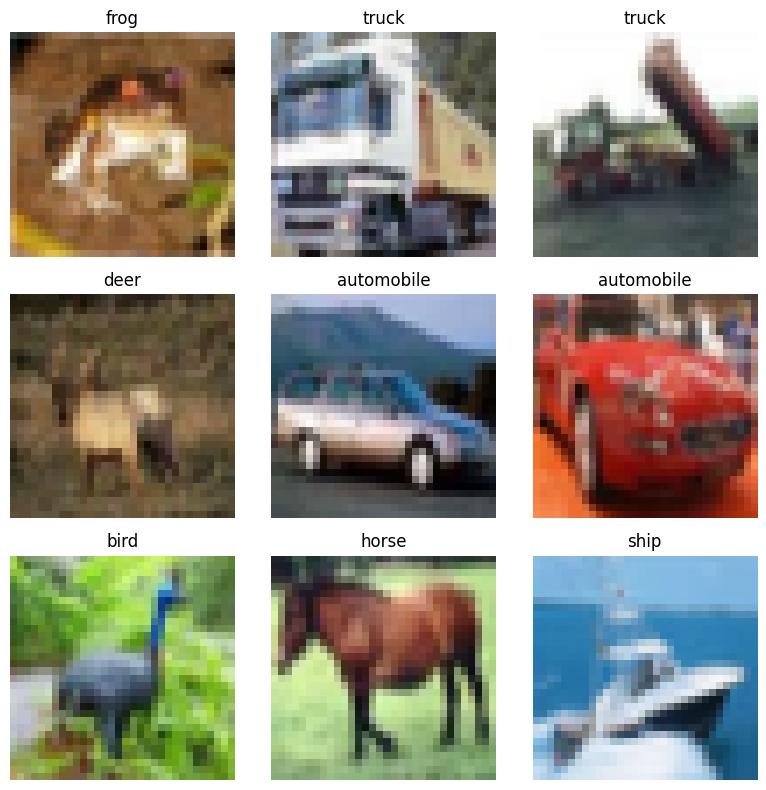

In [ ]:

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(x_train[i])

    # Convert the numerical label into its class name.
    label = int(y_train[i][0])
    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Convert pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Image data type:", x_train.dtype)


Minimum pixel value: 0.0
Maximum pixel value: 1.0
Image data type: float32


In [ ]:

# Build the CNN model

model_A = tf.keras.Sequential([
    # Input image: 32 x 32 pixels, 3 colour channels
    tf.keras.layers.Input(shape=(32, 32, 3)),

    # Convolution block 1
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a one-dimensional vector
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Output layer: 10 classes
    tf.keras.layers.Dense(10, activation="softmax")
],name="sequential")

model_A.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

model_A.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:

history_A = model_A.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=True
)


In [ ]:

test_loss_A, test_accuracy_A = model_A.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Run A Test Loss:", test_loss_A)
print("Run A Test Accuracy:", test_accuracy_A * 100, "%")


In [ ]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
])

print("Data augmentation pipeline created.")


In [ ]:

model_B = tf.keras.Sequential([
    # Augment the training images
    data_augmentation,

    # Same CNN architecture as Run A
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_B.summary()


In [ ]:

model_B = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_B.summary()


In [ ]:

model_B.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:

history_B = model_B.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=True
)


Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.4257 - loss: 1.5839 - val_accuracy: 0.5388 - val_loss: 1.2938
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 54ms/step - accuracy: 0.5417 - loss: 1.2848 - val_accuracy: 0.5990 - val_loss: 1.1210
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 53ms/step - accuracy: 0.5879 - loss: 1.1656 - val_accuracy: 0.6504 - val_loss: 1.0046
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 54ms/step - accuracy: 0.6186 - loss: 1.0849 - val_accuracy: 0.6442 - val_loss: 1.0158
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.6364 - loss: 1.0361 - val_accuracy: 0.6688 - val_loss: 0.9613
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.6532 - loss: 0.9905 - val_accuracy: 0.6602 - val_loss: 0.9786
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 53ms/step - accuracy: 0.6657 - loss: 0.9537 - val_accuracy: 0.7024 - val_loss: 0.8688
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 38s 55ms/step - accuracy: 0.6754 - loss: 0.9250 - 

In [ ]:

test_loss_B, test_accuracy_B = model_B.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Run B Test Loss:", test_loss_B)
print("Run B Test Accuracy:", test_accuracy_B * 100, "%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7140 - loss: 0.8424
Run B Test Loss: 0.8423756957054138
Run B Test Accuracy: 71.39999866485596 %


In [ ]:

print("Run A (without augmentation):",
      round(test_accuracy_A * 100, 2), "%")

print("Run B (with augmentation):",
      round(test_accuracy_B * 100, 2), "%")

difference = (test_accuracy_B - test_accuracy_A) * 100

print("Accuracy difference:",
      round(difference, 2), "percentage points")

if difference > 0:
    print("Augmentation improved test accuracy.")
elif difference < 0:
    print("Augmentation reduced test accuracy.")
else:
    print("Both runs have equal test accuracy.")


Run A (without augmentation): 70.53 %
Run B (with augmentation): 71.4 %
Accuracy difference: 0.87 percentage points
Augmentation improved test accuracy.


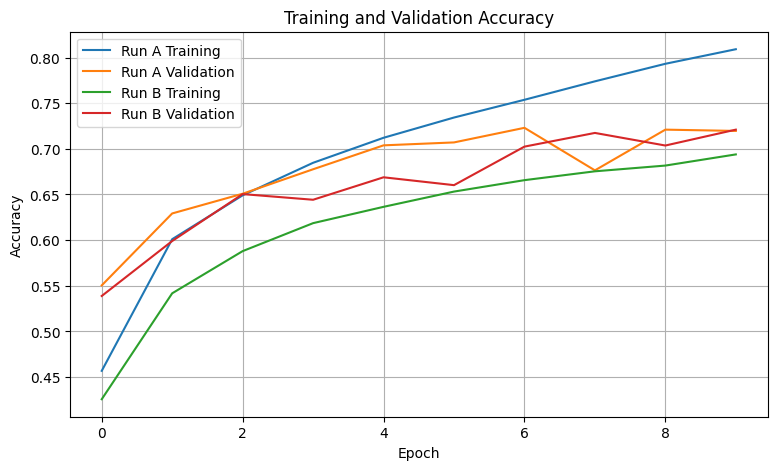

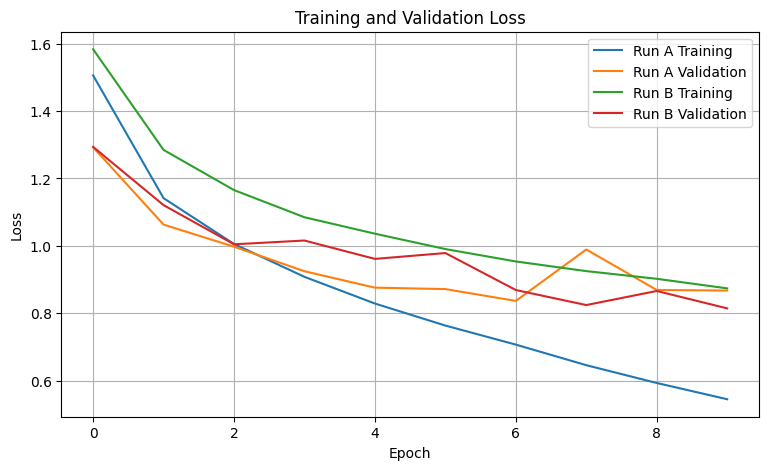

In [ ]:

# Accuracy comparison
plt.figure(figsize=(9, 5))

plt.plot(history_A.history["accuracy"],
         label="Run A Training")

plt.plot(history_A.history["val_accuracy"],
         label="Run A Validation")

plt.plot(history_B.history["accuracy"],
         label="Run B Training")

plt.plot(history_B.history["val_accuracy"],
         label="Run B Validation")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Loss comparison
plt.figure(figsize=(9, 5))

plt.plot(history_A.history["loss"],
         label="Run A Training")

plt.plot(history_A.history["val_loss"],
         label="Run A Validation")

plt.plot(history_B.history["loss"],
         label="Run B Training")

plt.plot(history_B.history["val_loss"],
         label="Run B Validation")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

if test_accuracy_A >= test_accuracy_B:
    best_model = model_A
    best_run = "Run A (without augmentation)"
else:
    best_model = model_B
    best_run = "Run B (with augmentation)"

print("Better model:", best_run)
print("Test accuracy:",
      round(max(test_accuracy_A, test_accuracy_B) * 100, 2), "%")


Better model: Run B (with augmentation)
Test accuracy: 71.4 %


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


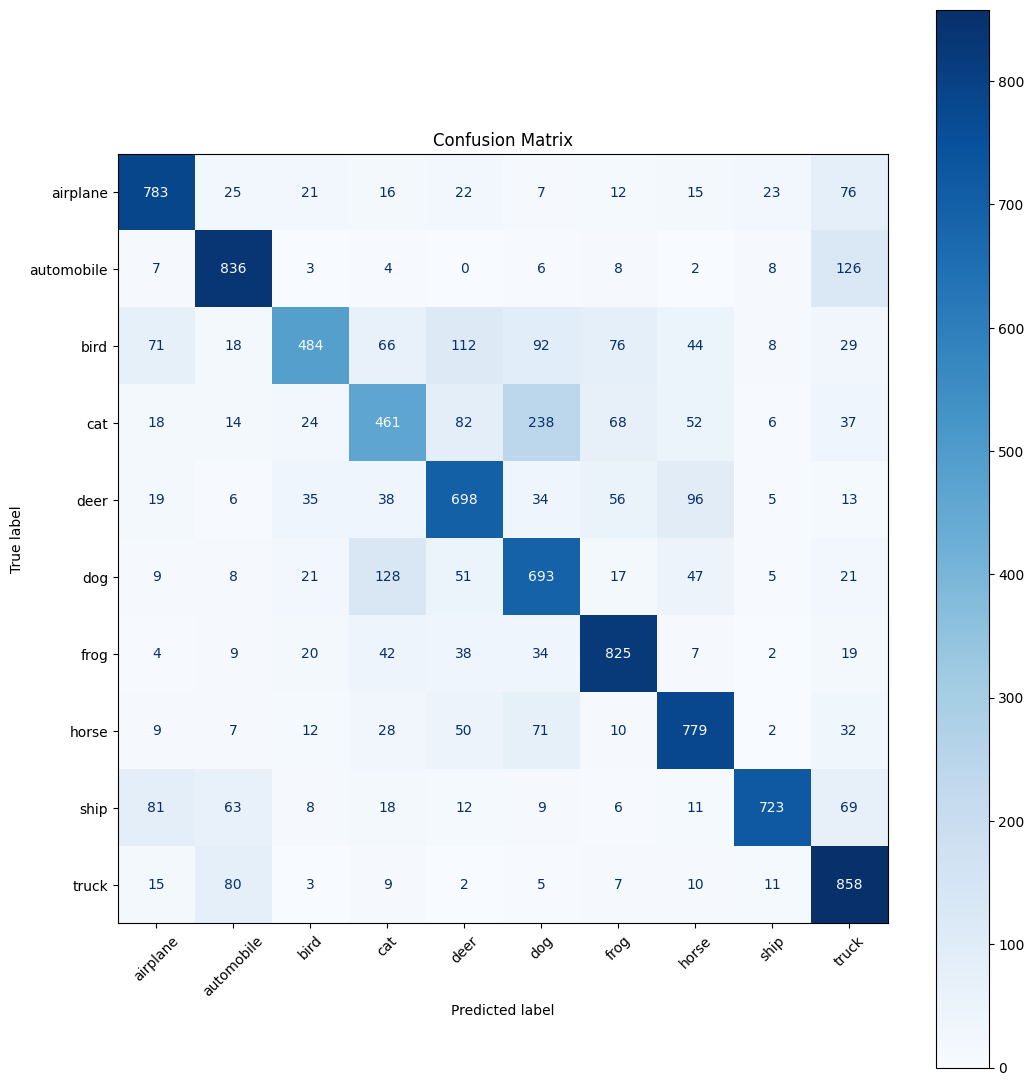

In [ ]:

# Predict the classes of the test images
predictions = best_model.predict(x_test, verbose=1)

# Convert the output scores into predicted class numbers
y_pred = np.argmax(predictions, axis=1)

# Convert the true labels into a one-dimensional array
y_true = y_test.flatten()

# Generate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 11))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Copy the matrix so the original remains unchanged
cm_off_diagonal = cm.copy()

# Remove correct predictions from consideration
np.fill_diagonal(cm_off_diagonal, 0)

# Find the largest remaining value
i, j = np.unravel_index(
    np.argmax(cm_off_diagonal),
    cm_off_diagonal.shape
)

print("Most confused actual class:", class_names[i])
print("Most confused predicted class:", class_names[j])
print("Number of such mistakes:", cm_off_diagonal[i, j])


Most confused actual class: cat
Most confused predicted class: dog
Number of such mistakes: 238


In [ ]:
fig.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.savefig("accuracy_curves.png", dpi=200, bbox_inches="tight")
plt.savefig("loss_curves.png", dpi=200, bbox_inches="tight")

from google.colab import files

files.download("accuracy_curves.png")
files.download("loss_curves.png")
files.download("confusion_matrix.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>